In [1]:
import numpy as np
import pandas as pd
from datetime import datetime, timedelta
from time import perf_counter
import matplotlib.pyplot as plt
from scipy.optimize import linprog
import pickle
import json
from oplem.Assets import StorageAsset as ev  #https://github.com/EsaLaboratory/OPLEM
from collections import defaultdict
from pathlib import Path
import picos as pc

plt.rcParams.update({'font.size': 12})

In [2]:
#method to proportionally resize a figure 
def set_size(width, fraction=1):
    """Set figure dimensions to avoid scaling in LaTeX"""
    """
    Parameters
   ----------
    width: float
            Document textwidth or columnwidth in pt,
    fraction: float, optional
            Fraction of the width which you wish the figure to occupy

    Returns
    -------
    fig_dim: tuple
            Dimensions of figure in inches
    """
    
    # Width of figure (in pts)\n",
    fig_width_pt = width * fraction

    # Convert from pt to inches
    inches_per_pt = 1 / 72.27
        
    # Golden ratio to set aesthetic figure height\n",
    # https://disq.us/p/2940ij3\n",
    golden_ratio = (5**.5 - 1) / 2

    # Figure width in inches\n",
    fig_width_in = fig_width_pt * inches_per_pt
    # Figure height in inches\n",
    fig_height_in = fig_width_in * golden_ratio

    fig_dim = (fig_width_in, fig_height_in)

    return fig_dim

In [3]:
np.random.seed(1000)

#assumption: we assume all cars leave with 85% charge
desired_rate = 0.85
arrival_rate = 0.2

#time horizon
dt_ems =0.25
T_ems = int(24/dt_ems)
dt, T = dt_ems, T_ems

# 1. Dataset loading pipeline

In [4]:
def split_session_by_day(
    arrival,
    departure,
    dt_hours=0.25,
    conservative=True
):
    """
    Return:
        [(date, availability_vector), ...]

    for all days touched by the charging session.
    """

    T = int(round(24 / dt_hours))

    output = []

    current_day = arrival.normalize()
    final_day = departure.normalize()

    while current_day <= final_day:

        next_day = ( current_day + pd.Timedelta(days=1) )

        # Intersection between charging session
        # and this day.
        start = max( arrival, current_day )
        end = min( departure, next_day )

        if end <= start:
            current_day = next_day
            continue

        start_float = (start - current_day).total_seconds() / (dt_hours * 3600)
        end_float = (end - current_day).total_seconds() / (dt_hours * 3600)

        if conservative:

            start_idx = int(np.ceil(start_float) )
            end_idx = int( np.floor(end_float)  )

        else:

            start_idx = int( np.floor(start_float))
            end_idx = int(   np.ceil(end_float))

        start_idx = np.clip( start_idx, 0, T )
        end_idx = np.clip( end_idx, 0, T )
        availability = np.zeros(T)

        if end_idx > start_idx:

            availability[ start_idx:end_idx] = 1
            output.append( (current_day.date(),availability ))

        current_day = next_day

    return output

In [5]:
def get_available_duration(
    arrival,
    departure,
    dt_hours=0.25
):
    daily_availability = split_session_by_day( arrival, departure, dt_hours=dt_hours, conservative=True )
    n_available_slots = sum( np.sum(availability) for _, availability in daily_availability)
    return n_available_slots * dt_hours
    
    
def prepare_ev_sessions(
    df,
    column_map,
    dt_hours = 0.25,
    departure_soc=1
):
    """
    Standardize an EV charging dataset.

    If SOC_arr and SOC_dep are provided in column_map,
    they are used directly. Otherwise, they are estimated from:
        capacity_kwh
        energy_kwh
        soc_arr
    """

    # Rename dataset-specific columns
    rename_map = { original: standard for standard, original in column_map.items() }

    df = df.rename(columns=rename_map).copy()

    required = ["power_kw", "capacity_kwh", "arrival", "departure"]

    df = df.dropna(subset=required)

    df["arrival"] = pd.to_datetime(df["arrival"])
    df["departure"] = pd.to_datetime(df["departure"])

    # Basic validity checks
    df = df[
        (df["capacity_kwh"] > 0)
        & (df["power_kw"] > 0)
        & (df["departure"] > df["arrival"])
    ].copy()

    # =========================================================
    # CASE 1: SOC_arr and SOC_dep exist in the dataset
    # =========================================================

    has_soc = ( "soc_arr" in df.columns  and "soc_dep" in df.columns )

    if has_soc:
        df = df.dropna( subset=["soc_arr", "soc_dep"] )

        # Optional sanity filtering
        df = df[ df["soc_arr"].between(0, 1)
              & df["soc_dep"].between(0, 1)
        ].copy()

    # =========================================================
    # CASE 2: SOC values are not available -> approximate
    # =========================================================

    else:

        if "energy_kwh" not in df.columns:
            raise ValueError( "SOC_arr/SOC_dep are unavailable and energy_kwh is also missing, so SOC cannot be estimated with the selected method." )

        df = df.dropna( subset=["energy_kwh"] )

        df = df[
            (df["energy_kwh"] >= 0)
            & (df["energy_kwh"]<= df["capacity_kwh"] )
        ].copy()

        capacity = df["capacity_kwh"]
        energy = df["energy_kwh"]
    
        available_duration = df.apply(
            lambda row: get_available_duration( row["arrival"], row["departure"], dt_hours=dt_hours, ),
            axis=1,
        )
        
        max_charge_energy = ( df["power_kw"] * available_duration )
        
        rechargeable_energy = np.minimum(  energy, max_charge_energy, )
        
        # Assume full SOC at departure
        df["soc_dep"] = departure_soc
        
        # Infer arrival SOC
        df["soc_arr"] = ( departure_soc  - rechargeable_energy / capacity )

    return df

In [6]:
def plot_dataset_stats(
    df,
    capacity_col="capacity_kwh",
    soc_arr_col="soc_arr",
    soc_dep_col="soc_dep",
    bins=20,
    save_path=None
):
    """
    Plot distributions of battery capacity,
    arrival SOC, and departure SOC.
    """

    fig, ax = plt.subplots( 3,  figsize=set_size(516))

    # Battery capacity
    ax[0].hist( df[capacity_col].dropna(), bins=bins, edgecolor="white", label="$C_{\max}$ [kWh]"  )
    ax[0].legend()
    #ax[0].set_xlabel("Battery capacity [kWh]")
    #ax[0].set_ylabel("Number of sessions")
    #ax[0].set_title(r"$C_{\max}$")

    # Arrival SOC
    ax[1].hist(
        df[soc_arr_col].dropna(), bins=bins, edgecolor="white", label=r"$SOC_{\mathrm{arr}}$ [%]")
    ax[1].legend()
    #ax[1].set_xlabel(r"$SOC_{\mathrm{arr}}$")
    ax[1].set_ylabel("Number of sessions")
    #ax[1].set_title(r"$SOC_{\mathrm{arr}}$")
    ax[1].set_xlim(0, 1)

    # Departure SOC
    ax[2].hist( df[soc_dep_col].dropna(), bins=bins, edgecolor="white", label=r"$SOC_{\mathrm{dep}}$ [%]")
    ax[2].legend()
    #ax[2].set_xlabel(r"$SOC_{\mathrm{dep}}$")
    #ax[2].set_ylabel("Number of sessions")
    #ax[2].set_title(r"$SOC_{\mathrm{dep}}$")
    ax[2].set_xlim(0, 1)

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path,bbox_inches="tight")

    plt.show()

## 1.1 application on 2 datasets

In [7]:
#Residential dataset
df_res = pd.read_excel('v2x_forecasting/Data/residential/CrowdCharge-Transactions.xlsx', sheet_name='Transaction Data')

column_map_res = {
   # "charger_id": "ChargerID",
    #"participant_id": "ParticipantID",
    "power_kw": "CarKW",
    "capacity_kwh": "CarKWh",
    "arrival": "AdjustedStartTime",
    "departure": "AdjustedStopTime",
    "energy_kwh": "ConsumedkWh"
}

sessions_res = prepare_ev_sessions(df_res,column_map_res)

######################################################################################################

#Commercial dataset
df_com = pd.read_excel('v2x_forecasting/Data/commercial/Session_data.xlsx', sheet_name='Session_data')
df_com["Pmax (kW)"] = df_com["Pmax (W)"] / 1000       
df_com["Energy Capacity (kWh)"] = df_com["Energy capacity (Wh)"] / 1000       
df_com["SOC arrival"] = df_com["SOC arrival"] / 100  
df_com["SOC departure"] = df_com["SOC departure"] / 100  

column_map_com = {
   # "charger_id": "ChargerID",
    #"participant_id": "ParticipantID",
    "power_kw": "Pmax (kW)",
    "capacity_kwh": "Energy Capacity (kWh)",
    "arrival": "Arrival",
    "departure": "Departure",
    "energy_kwh": "Energy (Wh)",
    "soc_arr": "SOC arrival",
    "soc_dep": "SOC departure"
}

sessions_com = prepare_ev_sessions(df_com,column_map_com)


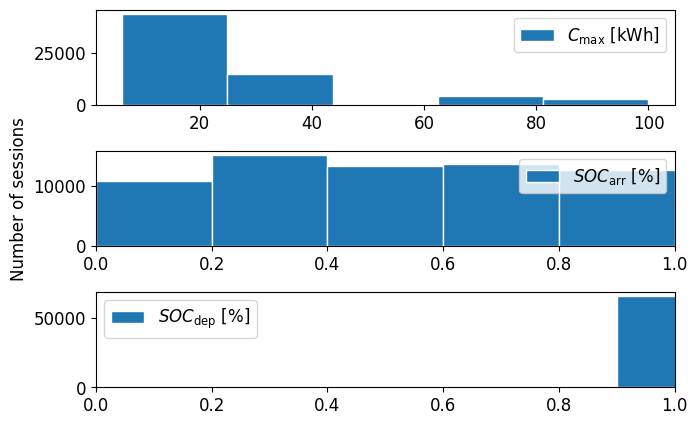

In [8]:
file_name = Path.cwd() / "stats_res.pdf"
plot_dataset_stats(sessions_res, bins=5, save_path=file_name)

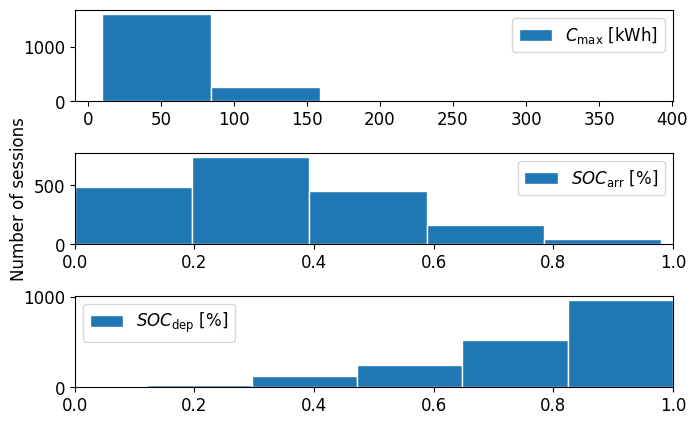

In [9]:
file_name = Path.cwd() / "stats_com.pdf"
plot_dataset_stats(sessions_com, bins=5, save_path=file_name)

# 2. Create polytopes

Form of polytope dict:

polytopes = {

    "2024-01-01": [b1, b2, b3, ...],
    
    "2024-01-02": [b1, b2, ...],
    
}

In [10]:
def compute_daily_energy_targets(
    daily_availability,
    cap_arr,
    cap_dep
):

    slot_counts = np.array([ np.sum(availability)
        for _, availability in daily_availability ])

    total_slots = slot_counts.sum()

    if total_slots <= 0:
        return []

    delta_E = cap_dep - cap_arr

    targets = []

    cumulative = 0

    for (date, availability), n_slots in zip(daily_availability, slot_counts):

        f_start = (cumulative / total_slots)
        cumulative += n_slots
        f_end = ( cumulative / total_slots )

        E0 = (cap_arr + f_start * delta_E )
        ET = (cap_arr  + f_end * delta_E )

        targets.append(
            (date, availability, E0, ET)
        )

    return targets

In [11]:
def adapt_polytope_to_availability(
    b_i,
    Emin,
    E0,
    ET,
    availability,
    dt_hours,
    alpha=1.0,
):
    """
    Adapt the battery RHS vector b_i to an EV availability window.

    Parameters
    ----------
    b_i : array-like
        Original battery RHS vector, shape (6*T,) or (6*T, 1).

    Emin : float
        Minimum battery energy [kWh].

    E0 : float
        Energy at EV arrival, C_arr [kWh].

    ET : float
        Required energy at EV departure, C_dep [kWh].

    availability : array-like
        Binary availability vector of length T.
        1 = EV connected, 0 = EV unavailable.

    dt_hours : float
        Time-step duration in hours.

    alpha : float, default=1.0
        Self-discharge factor per time step.

    Returns
    -------
    b_ev : np.ndarray
        RHS vector adapted to EV availability.
    """

    b_ev = np.asarray(b_i, dtype=float).reshape(-1).copy()
    availability = np.asarray(availability, dtype=int).reshape(-1)

    T = len(availability)

    if len(b_ev) != 6 * T:
        raise ValueError(
            f"Expected b_i length {6*T}, got {len(b_ev)}."
        )

    # ---------------------------------------------------------
    # Identify connected interval
    # ---------------------------------------------------------
    connected = np.flatnonzero(availability == 1)

    if len(connected) == 0:
        raise ValueError("Availability vector contains no connected slots.")

    t_arr = connected[0]
    t_dep = connected[-1] + 1  # first unavailable slot after connection

    # Require one contiguous connection interval
    expected = np.arange(t_arr, t_dep)

    if not np.array_equal(connected, expected):
        raise ValueError(
            "Availability must contain one contiguous connection interval."
        )

    n_connected = t_dep - t_arr

    # ---------------------------------------------------------
    # Blocks in b
    # ---------------------------------------------------------
    # [0:T]       Pmax
    # [T:3T]      zero blocks
    # [3T:4T]     -Pmin
    # [4T:5T]     Cmax block
    # [5T:6T]     Cmin block

    # Power constraints:
    # EV cannot charge/discharge outside availability
    b_ev[0:T] *= availability
    b_ev[3*T:4*T] *= availability

    # Save original battery energy-bound trajectories
    cmax_battery = b_ev[4*T:5*T].copy()
    cmin_battery = b_ev[5*T:6*T].copy()

    # ---------------------------------------------------------
    # Cmax block
    # ---------------------------------------------------------
    cmax_ev = np.zeros(T)

    # During connection:
    # Cmax - alpha^tau * C_arr
    #
    # The original battery trajectory starts at tau = 0,
    # so shift it to start at t_arr.
    cmax_ev[t_arr:t_dep] = cmax_battery[:n_connected]
    cmax_ev[t_dep:] = cmax_ev[t_dep-1]

    # After departure no charging/discharging is possible, so
    # the energy upper-bound block is not needed.
    #
    # Before arrival it is also inactive.
    b_ev[4*T:5*T] = cmax_ev

    # ---------------------------------------------------------
    # Cmin block
    # ---------------------------------------------------------
    cmin_ev = np.zeros(T)

    # During connection:
    # alpha^tau * C_arr - Cmin
    cmin_ev[t_arr:t_dep] = cmin_battery[:n_connected]

    # Departure requirement from the EV formulation:
    #
    # alpha^(t_dep - t_arr) * C_arr - C_dep
    #
    # Once the EV has departed, this RHS is held constant.
    departure_rhs = (
        alpha ** n_connected * E0
        - ET
    )

    if t_dep < T:
        cmin_ev[t_dep-1:] = departure_rhs

    b_ev[5*T:6*T] = cmin_ev

    return b_ev

In [12]:
def build_polytope_dictionary(
    sessions,
    dt_hours=0.25,
    output_path=Path.cwd(),
    A_name="A.pkl",
    polytopes_name="polytopes.pkl"
):

    T = int(round(24 / dt_hours))

    polytopes = defaultdict(list)

    for _, row in sessions.iterrows():

        daily_availability = (
            split_session_by_day( row["arrival"], row["departure"], dt_hours=dt_hours, conservative=True)
        )

        daily_targets = (
            compute_daily_energy_targets( daily_availability, row['capacity_kwh']*row["soc_arr"],  row['capacity_kwh']*row["soc_dep"] )
        )

        for (date, availability, E0, ET) in daily_targets:

            # -----------------------------------------
            # Correct unreachable departure energy
            # -----------------------------------------
            n_connected = np.count_nonzero(availability)
        
            max_charge_energy = (
                row["power_kw"]
                * n_connected
                * dt_hours
            )
        
            #ET_max_reachable = ( E0 + max_charge_energy)
            ET_max_reachable = min( row["capacity_kwh"], E0 + max_charge_energy)

            ET = min(ET, ET_max_reachable)
            
            # -----------------------------------------
            # Build EV polytope
            # -----------------------------------------
            Emax = (row["capacity_kwh"]* np.ones(T))
            Emin = np.zeros(T)

            Pmax = ( row["power_kw"]* availability )
            Pmin = -Pmax

            ev_i = ev(Emax, Emin, Pmax, Pmin, E0, ET, 1, dt_hours, T, dt_hours, T)
            A, b_i = ev_i.polytope()

            b_i = adapt_polytope_to_availability( b_i, ev_i.Emin, ev_i.E0, ev_i.ET, availability, dt_hours)

            polytopes[str(date)].append( np.asarray(b_i) )

    polytopes = dict(polytopes)

    if output_path is None:
        output_path = Path.cwd()
    else:
        output_path = Path(output_path)

    output_path.mkdir(parents=True, exist_ok=True)

    # Save A
    with open(output_path / A_name, "wb") as fp:
        pickle.dump(A, fp)

    # Save polytopes
    with open(output_path / polytopes_name, "wb") as fp:
        pickle.dump(polytopes, fp)


    return A, polytopes

In [14]:
def prepare_aggregate_polytope(
    polytopes,
    dt_hours=0.25,
    output_path=Path.cwd(),
    name="dataset",
    save=True
):
    """
    Aggregate daily EV polytopes and convert them into
    a time-indexed DataFrame.

    Parameters
    ----------
    polytopes : dict
        Dictionary of the form:
        {
            date: [b_1, b_2, ..., b_N]
        }

    dt_hours : float, default=0.25
        Time resolution in hours.
        Example: 0.25 = 15 min.

    output_path : str or Path, optional
        Directory in which files are saved.

    name : str, default="dataset"
        Dataset identifier used for saved filenames.

    save : bool, default=True
        Whether to save the aggregated polytope and DataFrame.

    Returns
    -------
    polytope_agg : dict
        Dictionary:
        {
            date: b_agg
        }

    df : pandas.DataFrame
        Time-indexed aggregate flexibility DataFrame.
    """

    T = int(round(24 / dt_hours))

    # ==========================================
    # 1. Aggregate individual EV polytopes
    # ==========================================

    polytope_agg = {}

    for day, b_list in polytopes.items():
####################################################################################
        for i, b in enumerate(b_list):

            if b is None:
                print(
                    f"Whole polytope is None: "
                    f"day={day}, EV={i}"
                    )
                continue

            b_test = np.asarray(b)

            none_positions = [
                j
                for j, value in enumerate(
                    b_test.reshape(-1)
                )
                if value is None
                ]

            if none_positions:
                print(
                f"None inside polytope: "
                f"day={day}, EV={i}, "
                f"positions={none_positions[:10]}"
            )

            if len(b_list) == 0:
                continue
        ###############################################

        b_array = np.stack([
            np.asarray(b).reshape(-1)
            for b in b_list
        ])

        b_agg = np.nansum(
            b_array,
            axis=0
        )

        if len(b_agg) != 6 * T:
            raise ValueError(
                f"{day}: expected aggregated b "
                f"of length {6*T}, got {len(b_agg)}."
            )

        polytope_agg[str(day)] = b_agg

    if len(polytope_agg) == 0:
        raise ValueError(
            "No non-empty daily polytopes were found."
        )

    # ==========================================
    # 2. Convert aggregate b -> DataFrame
    # ==========================================

    rows = []

    for day, b in polytope_agg.items():

        day_start = pd.Timestamp(day).normalize()

        timestamps = pd.date_range( start=day_start, periods=T, freq=pd.to_timedelta(dt_hours, unit="h")   )


        ##############################################################################
        

        daily_df = pd.DataFrame(
            {
            "Pmax": b[0:T],
            "Pmin": b[3*T:4*T],
            "Cmax": b[4*T:5*T],
            "Cmin": b[5*T:6*T]
            },
        index=timestamps
        )

        rows.append(daily_df)

    df = pd.concat(rows).sort_index()


    # ==========================================
    # 3. Calendar features
    # ==========================================

    df["Month"] = df.index.month

    df["IsWeekend"] = (
        df.index.dayofweek >= 5
    ).astype(int)

    # ==========================================
    # 4. Save
    # ==========================================

    if save:

        if output_path is None:
            output_path = Path.cwd()
        else:
            output_path = Path(output_path)

        output_path.mkdir(
            parents=True,
            exist_ok=True
        )

        # Daily aggregated b dictionary
        with open(
            output_path
            / f"polytope_agg_{name}.pkl",
            "wb"
        ) as f:

            pickle.dump(
                polytope_agg,
                f
            )

        # Time-indexed dataset
        df.to_pickle(
            output_path
            / f"polytope_agg_{name}_df.pkl"
        )

    return polytope_agg, df

In [15]:
def plot_aggregate_polytope(
    df,
    save=True,
    output_path=Path.cwd(),
    filename="aggregate_polytope.pdf",
    figsize=None,
    font_size=12
):

    plt.rcParams.update({
        "font.size": font_size
    })

    # ------------------------------------------
    # Figure size
    # ------------------------------------------

    if figsize is None:
        figsize = set_size(516)

    # ------------------------------------------
    # Check columns
    # ------------------------------------------

    required = [
        "Pmax",
        "Pmin",
        "Cmax",
        "Cmin"
    ]

    missing = [
        col
        for col in required
        if col not in df.columns
    ]

    if missing:
        raise ValueError(
            f"Missing columns: {missing}"
        )

    # ==========================================
    # Plot
    # ==========================================

    fig, axs = plt.subplots(
        2,
        figsize=figsize,
        sharex=True
    )

    # ------------------------------------------
    # Power flexibility
    # ------------------------------------------

    axs[0].plot(
        -df["Pmin"],
        linestyle = '-.',
        label=r"$b_{P_{\min}}^{agg}$"
    )

    axs[0].plot(
        df["Pmax"],
        label=r"$b_{P_{\max}}^{agg}$"
    )

    axs[0].set_ylabel("Aggregate RHS [kW]")
    axs[0].legend()
    axs[0].grid(alpha=0.2)

    # ------------------------------------------
    # Energy flexibility
    # ------------------------------------------

    axs[1].plot(
        df["Cmin"],
        linestyle = '-.',
        label=r"$b_{C_{\min}}^{agg}$"
    )
    
    axs[1].plot(
        df["Cmax"],
        label=r"$b_{C_{\max}}^{agg}$"
    )

    axs[1].set_ylabel("Aggregate RHS [kWh]")
    axs[1].set_xlabel("Time step")

    axs[1].legend()
    axs[1].grid(alpha=0.2)

    fig.tight_layout()

    # ==========================================
    # Save
    # ==========================================

    if save:

        if output_path is None:
            output_path = Path.cwd()
        else:
            output_path = Path(output_path)

        output_path.mkdir(
            parents=True,
            exist_ok=True
        )

        fig.savefig(
            output_path / filename,
            bbox_inches="tight"
        )

    plt.show()

    return fig, axs

## 2.1 polytope application on both datasets

In [16]:
A_res, polytopes_res = build_polytope_dictionary(sessions_res, A_name="A_res.pkl", polytopes_name="polytopes_res.pkl")

In [17]:
polytope_agg_res, df_agg_res = prepare_aggregate_polytope(polytopes=polytopes_res, name="res")

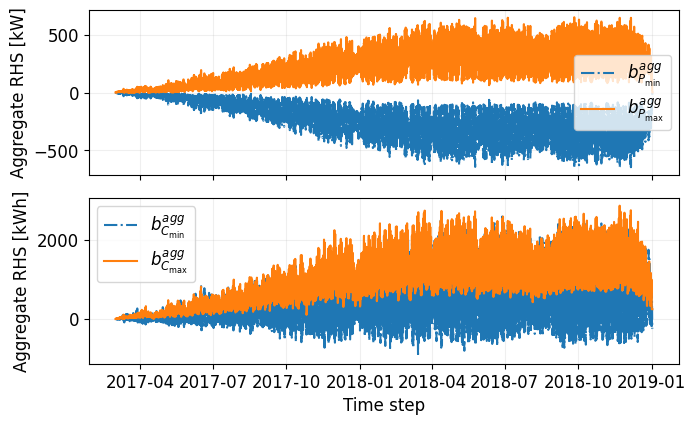

(<Figure size 713.989x441.27 with 2 Axes>,
 array([<Axes: ylabel='Aggregate RHS [kW]'>,
        <Axes: xlabel='Time step', ylabel='Aggregate RHS [kWh]'>],
       dtype=object))

In [18]:
plot_aggregate_polytope(df_agg_res, filename="bagg_res.pdf")

In [19]:
A_com, polytopes_com = build_polytope_dictionary(sessions_com, A_name="A_com.pkl", polytopes_name="polytopes_com.pkl")

In [20]:
polytope_agg_com, df_agg_com = prepare_aggregate_polytope(polytopes=polytopes_com, name="com")

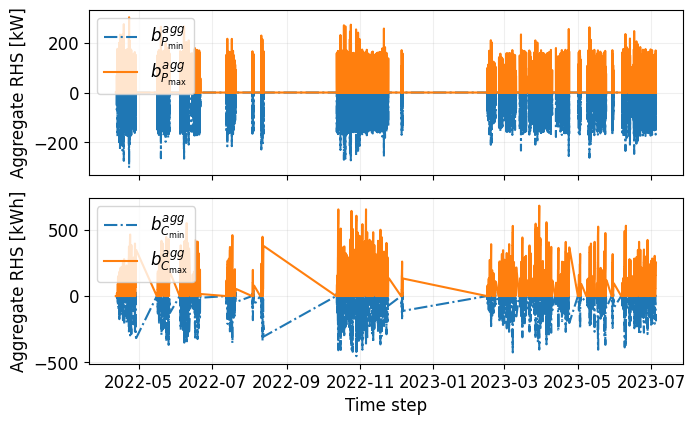

(<Figure size 713.989x441.27 with 2 Axes>,
 array([<Axes: ylabel='Aggregate RHS [kW]'>,
        <Axes: xlabel='Time step', ylabel='Aggregate RHS [kWh]'>],
       dtype=object))

In [21]:
plot_aggregate_polytope(df_agg_com, filename="bagg_com.pdf")

## 2.2 Reference model for comparison (Exact Minkowski aggregation)

In [22]:
def generate_c_vectors(T, seed=42):

    rng = np.random.default_rng(seed)

    c_vectors = []

    # ------------------------------------------
    # 1. Maximum charging
    # ------------------------------------------

    c_charge = np.concatenate([
        np.ones(T),
        np.zeros(T)
    ])

    c_vectors.append(
        ("max_charge", c_charge)
    )

    # ------------------------------------------
    # 2. Maximum discharging
    # ------------------------------------------

    c_discharge = np.concatenate([
        np.zeros(T),
        -np.ones(T)
    ])

    c_vectors.append(
        ("max_discharge", c_discharge)
    )

    # ------------------------------------------
    # 3-7. Random directions
    # ------------------------------------------

    for k in range(1, 4):

        signal = rng.uniform(
            -1,
            1,
            T
        )

        # Net-power direction:
        # p_net = p_ch - p_dis
        c_random = np.concatenate([
            signal,
            -signal
        ])

        c_random = c_random / np.linalg.norm(c_random)

        c_vectors.append(
            (f"random_{k}", c_random)
        )

    return c_vectors

In [23]:
def solve_exact(A, b_list, c, solver='cvxopt', verbosity=0):

    N = len(b_list)
    n_p = A.shape[1]

    # ---------------------------------
    # Construct exact problem
    # ---------------------------------

    start = perf_counter()

    problem = pc.Problem()

    A_pc = pc.Constant(
        "A",
        np.asarray(A)
    )

    c_pc = pc.Constant(
        "c",
        np.asarray(c).reshape(-1)
    )

    p_vars = []

    for i, b_i in enumerate(b_list):

        p_i = pc.RealVariable(
            f"p_{i}",
            n_p
        )

        b_pc = pc.Constant(
            f"b_{i}",
            np.asarray(b_i).reshape(-1)
        )

        problem.add_constraint(
            A_pc * p_i <= b_pc
        )

        p_vars.append(p_i)

    # Aggregate power only for objective
    p_total = p_vars[0]

    for p_i in p_vars[1:]:
        p_total = p_total + p_i

    problem.set_objective(
        "max",
        c_pc | p_total
    )

    build_time = (
        perf_counter() - start
    )

    # ---------------------------------
    # Solve exact problem
    # ---------------------------------

    start = perf_counter()

    problem.solve(
        solver=solver,
        verbosity=verbosity
    )

    solve_time = (
        perf_counter() - start
    )

    # Exact aggregate schedule
    p_total_value = np.sum(
        [
            np.asarray(p.value).reshape(-1)
            for p in p_vars
        ],
        axis=0
    )

    objective = float(
        np.dot(c, p_total_value)
    )

    total_time = (
        build_time
        + solve_time
    )

    return {
        "objective": objective,
        "p": p_total_value,
        "build_time": build_time,
        "solve_time": solve_time,
        "total_time": total_time
    }

In [30]:
def solve_aggregate(A, b_list, c, solver='cvxopt', verbosity=0):

    # ---------------------------------
    # Aggregate b
    # ---------------------------------

    start = perf_counter()
    b_agg = np.sum(  np.stack(b_list), axis=0 )
    aggregation_time = (  perf_counter() - start )

    # ---------------------------------
    # Construct PICOS problem
    # ---------------------------------

    start = perf_counter()
    n_p = A.shape[1]
    problem = pc.Problem()

    p = pc.RealVariable( "p_agg",  n_p  )

    A_pc = pc.Constant(  "A", np.asarray(A) )
    b_pc = pc.Constant("b_agg",np.asarray(b_agg).reshape(-1))
    c_pc = pc.Constant( "c",  np.asarray(c).reshape(-1))

    problem.add_constraint( A_pc * p <= b_pc )

    problem.set_objective( "max", c_pc | p )

    build_time = ( perf_counter() - start)

    # ---------------------------------
    # Solve
    # ---------------------------------

    start = perf_counter()

    ######################################################################################################
    try:

        solution = problem.solve(
        solver=solver,
        verbosity=verbosity
    )

    except Exception as e:
    
        print("\nAggregate optimization failed")
        print("Solver:", solver)
        print("A shape:", np.asarray(A).shape)
        print("b_agg shape:", np.asarray(b_agg).shape)
        print("c shape:", np.asarray(c).shape)
    
        print("b_agg finite:", np.all(np.isfinite(b_agg)))
    
        print("A finite:", np.all(np.isfinite(A)))
    
        print("c finite:", np.all(np.isfinite(c)))
    
        print("b_agg min/max:", np.nanmin(b_agg), np.nanmax(b_agg))
    
        raise
        ###########################################################################################################

    #problem.solve(
    #    solver="cvxopt",
    #    verbosity=0
    #)

    solve_time = (  perf_counter() - start )
    
    p_value = np.asarray( p.value ).reshape(-1)

    objective = float(  np.dot(c, p_value) )

    total_time = ( aggregation_time + build_time + solve_time  )

    return {
        "objective": objective,
        "p": p_value,
        "aggregation_time": aggregation_time,
        "build_time": build_time,
        "solve_time": solve_time,
        "total_time": total_time
    }

In [25]:
CHECKPOINT_COLUMNS = [
    "N_EV",
    "direction",
    "status",
    "failed_stage",
    "error",

    "F_exact",
    "F_aggregate",

    "approx_error_percent",

    "exact_build_s",
    "exact_solve_s",
    "exact_total_s",

    "aggregation_s",
    "aggregate_build_s",
    "aggregate_solve_s",
    "aggregate_total_s",

    "aggregate_speedup",
]

def save_checkpoint(row, checkpoint_file):

    row_df = pd.DataFrame([row], columns=CHECKPOINT_COLUMNS)

    write_header = not checkpoint_file.exists()

    row_df.to_csv( checkpoint_file, mode="a", header=write_header, index=False)

In [26]:
def benchmark_fleet(
    A,
    b_list,
    fleet_sizes,
    T,
    solver,
    output_path=Path.cwd(),
    name="benchmark",
    seed=42,
    verbosity=0
):

    if output_path is None:
        output_path = Path.cwd()
    else:
        output_path = Path(output_path)

    output_path.mkdir( parents=True, exist_ok=True)

    checkpoint_file = ( output_path / f"{name}_checkpoint.csv"    )

    if checkpoint_file.exists()  and checkpoint_file.stat().st_size > 0:

        existing = pd.read_csv( checkpoint_file)

        completed = set(
            zip(existing.loc[ existing["status"] == "success", "N_EV"],
                existing.loc[existing["status"] == "success","direction"])
                  )

    else:
        completed = set()

    c_vectors = generate_c_vectors( T=T, seed=seed)

    for N in fleet_sizes:

        if N > len(b_list):
            print(
                f"Skipping N={N}: only "
                f"{len(b_list)} EVs available."
            )
            continue

        print(f"\n===== N = {N} =====")

        fleet = b_list[:N]

        for c_name, c in c_vectors:
            if (N, c_name) in completed:

                print(f"  {c_name}: already completed, skipping" )

                continue

            print( f"  Running {c_name}...", flush=True)

            row = {
                "N_EV": N,
                "direction": c_name,
                "status": "started"
            }

            try:

                # =============================
                # Exact
                # =============================
                print( "Running Exact")

                exact = solve_exact(
                    A=A,
                    b_list=fleet,
                    c=c,
                    solver=solver,
                    verbosity = verbosity
                )

                # =============================
                # Aggregate
                # =============================
                print( "Running Agg")

                agg = solve_aggregate(
                    A=A,
                    b_list=fleet,
                    c=c,
                    solver=solver,
                    verbosity = verbosity
                )

                # =============================
                # Objectives
                # =============================

                F_exact = exact["objective"]
                F_agg = agg["objective"]

                # =============================
                # Errors
                # =============================

                if abs(F_exact) > 1e-10:

                    approx_error = (100 * (F_agg - F_exact) / abs(F_exact) )

                else:
                    approx_error = np.nan


                # =============================
                # Timing
                # =============================
                aggregate_speedup = (
                    exact["total_time"]
                    / agg["total_time"]
                )

                # =============================
                # Result
                # =============================

                row = {

                    "N_EV": N,
                    "direction": c_name,
                    "status": "success",

                    "F_exact": F_exact,
                    "F_aggregate": F_agg,
                    
                    "approx_error_percent": approx_error,

                    "exact_build_s": exact["build_time"],

                    "exact_solve_s": exact["solve_time"],

                    "exact_total_s": exact["total_time"],

                    "aggregation_s": agg["aggregation_time"],

                    "aggregate_build_s": agg["build_time"],

                    "aggregate_solve_s": agg["solve_time"],

                    "aggregate_total_s": agg["total_time"],,

                    "aggregate_speedup": aggregate_speedup,
                }

            except Exception as e:

                print(
                    f"    FAILED: {e}",
                    flush=True
                )

                row = {
                    "N_EV": N,
                    "direction": c_name,
                    "status": "failed",
                    "error": str(e)
                }

            # =================================
            # SAVE IMMEDIATELY
            # =================================

            save_checkpoint(row, checkpoint_file )

            print(  "    saved.", flush=True)

    # =========================================
    # Reload everything at the end
    # =========================================

    results = pd.read_csv(checkpoint_file )

    return results

In [27]:
def summary_from_results(results):
    summary = (results
    .groupby("N_EV")
    .agg(

        # Accuracy of aggregate polytope
        mean_approx_error=( "approx_error_percent", "mean" ),

        max_approx_error=( "approx_error_percent",  "max"),

        mean_tot_error=( "tot_error_percent", "mean" ),

        max_tot_error=( "tot_error_percent",  "max"),

        mean_scale_error=( "scale_error_percent", "mean" ),

        max_scale_error=( "scale_error_percent",  "max"),

        # Computation
        mean_exact_time=( "exact_total_s", "mean"),

        mean_aggregate_time=("aggregate_total_s", "mean" ),

        mean_proposed_time=( "proposed_total_s","mean" ),

        # Speedup
        median_aggregate_speedup=("aggregate_speedup","median"),

        median_total_speedup=("total_speedup","median")
    )
    .reset_index()
    )
    return summary

In [104]:
def plot_error_speedup(summary, savepath=None):
    fig, ax1 = plt.subplots(figsize=set_size(516))
    ax2 = ax1.twinx()

    # Left axis: aggregation error
    l1 = ax1.plot(
        summary["N_EV"],
        summary["mean_approx_error"],
        marker="o",
        label="Aggregation error"
    )

    # Right axis: speedup
    l2 = ax2.plot(
        summary["N_EV"],
        summary["median_aggregate_speedup"],
        marker="s",
        linestyle="--",
        label="Speedup"
    )

    ax1.set_xlabel("Fleet size, $N$")
    ax1.set_ylabel("Aggregation error [%]")
    ax2.set_ylabel("Speedup [$\\times$]")

    ax1.grid(alpha=0.3)

    # Combined legend
    lines = l1 + l2
    ax1.legend(lines, [l.get_label() for l in lines], loc="best")

    fig.tight_layout()

    if savepath:
        fig.savefig(savepath, bbox_inches="tight")

    return fig, ax1, ax2

## application

In [32]:
b_list_res = [  b for daily_b_list in polytopes_res.values()
                  for b in daily_b_list
             ]

results_res = benchmark_fleet(
    A=A_res,
    b_list=b_list_res,
    fleet_sizes=[10, 20, 30, 50, 60, 70, 80, 90, 100],
    solver = "gurobi",
    name ="res",
    T=T,
    seed=42,
    verbosity=0
)


===== N = 10 =====
  Running max_charge...
Running Exact
Running Agg
Running disagg
    saved.
  Running max_discharge...
Running Exact
Running Agg
Running disagg
    saved.
  Running random_1...
Running Exact
Running Agg
Running disagg
    saved.
  Running random_2...
Running Exact
Running Agg
Running disagg
    saved.
  Running random_3...
Running Exact
Running Agg
Running disagg
    saved.

===== N = 20 =====
  Running max_charge...
Running Exact
Running Agg
Running disagg
    saved.
  Running max_discharge...
Running Exact
Running Agg
Running disagg
    saved.
  Running random_1...
Running Exact
Running Agg
Running disagg
    saved.
  Running random_2...
Running Exact
Running Agg
Running disagg
    saved.
  Running random_3...
Running Exact
Running Agg
Running disagg
    saved.

===== N = 30 =====
  Running max_charge...
Running Exact
Running Agg
Running disagg
    saved.
  Running max_discharge...
Running Exact
Running Agg
Running disagg
    saved.
  Running random_1...
Running E

In [ ]:
summary_res = summary_from_results(results_res)

(<Figure size 713.989x441.27 with 2 Axes>,
 <Axes: xlabel='Fleet size, $N$', ylabel='Aggregation error [%]'>,
 <Axes: ylabel='Speedup [$\\times$]'>)

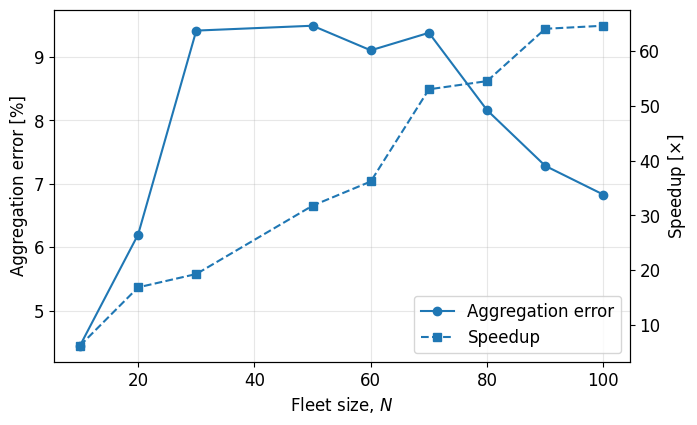

In [105]:
plot_error_speedup(summary_res, savepath="errorVsSpeedup.pdf")

# 3. Flexibility Estimation Case Study

In [11]:
import argparse
import json
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import picos as pc
import matplotlib.pyplot as plt


# ============================================================
# 1. CONFIGURATION
# ============================================================

DT = 0.25
T = 96
SEPARATOR_DATE = "2018-03-01"

# Half-open intervals: [start, end)
SERVICE_WINDOWS = {
    "15-17": (15.0, 17.0),
    "17.5-20": (17.5, 20.0),
}

BID_STRATEGIES = ("median", "q3")

poff, pon = 9.76/100, 20.03/100
TOUP = np.append(poff*np.ones(int(7/DT)), pon*np.ones(int(17/DT)))
FiT = 0.06*np.ones(T) 

LAMBDA_IMPORT = np.asarray(TOUP, dtype=float) / 100
LAMBDA_EXPORT = np.asarray(FiT, dtype=float) / 100

"""
# Import/export prices are in pence/kWh.
PRICE_IMPORT = [
    13.86, 13.86, 18.9, 18.9, 15.81, 15.81, 14.8, 14.8,
    15.81, 15.81, 14.78, 14.78, 16.59, 16.59, 15.75, 15.75,
    17.22, 17.22, 15.81, 15.81, 17.85, 17.85, 17.67, 17.67,
    22.63, 22.63, 22.44, 22.44, 23.1, 23.1, 25.41, 25.41,
    24.57, 24.57, 24.78, 24.78, 23.08, 23.08, 22.47, 22.47,
    20.58, 20.58, 19.53, 19.53, 17.85, 17.85, 17.84, 17.84,
    18.42, 18.42, 18.94, 18.94, 19.78, 19.78, 19.38, 19.38,
    21.82, 21.82, 21.82, 21.82, 22.26, 22.26, 25.2, 25.2,
    37.8, 37.8, 40.82, 40.82, 38.57, 38.57, 39.9, 39.9,
    40.82, 40.82, 40.32, 40.32, 25.35, 25.35, 24.15, 24.15,
    22.68, 22.68, 23.1, 23.1, 21.69, 21.69, 21.61, 21.61,
    20.66, 20.66, 17.89, 17.89, 21.84, 21.84, 18.96, 18.96,
]

PRICE_EXPORT_48 = [
    6.98, 9.24, 7.86, 7.41, 7.86, 7.4, 8.21, 7.83,
    8.49, 7.86, 8.77, 8.69, 10.91, 10.83, 11.12, 12.15,
    11.78, 11.87, 11.11, 10.84, 9.99, 9.52, 8.77, 8.76,
    9.02, 9.26, 9.63, 9.46, 10.55, 10.55, 10.74, 12.06,
    17.39, 18.74, 17.73, 18.33, 18.74, 18.52, 12.13, 11.59,
    10.93, 11.12, 10.49, 10.45, 10.03, 8.79, 10.56, 9.27,
]

PRICE_EXPORT = np.repeat(PRICE_EXPORT_48, 2)


# Convert pence/kWh to GBP/kWh.
LAMBDA_IMPORT = np.asarray(PRICE_IMPORT, dtype=float) / 100
LAMBDA_EXPORT = np.asarray(PRICE_EXPORT, dtype=float) / 100
"""

# Feasibility tolerance in kW.
TOL = 1e-5


# ============================================================
# 2. COMMON HELPERS
# ============================================================

def load_pickle(path):
    with open(path, "rb") as handle:
        return pickle.load(handle)


def service_indices(window):
    start, end = SERVICE_WINDOWS[window]
    return np.arange(
        round(start / DT),
        round(end / DT),
        dtype=int,
    )


def validate_polytope(A, b):
    A = np.asarray(A, dtype=float)
    b = np.asarray(b, dtype=float).reshape(-1)

    if A.shape != (6 * T, 2 * T):
        raise ValueError(
            f"Expected A shape {(6*T, 2*T)}, got {A.shape}"
        )

    if b.shape != (6 * T,):
        raise ValueError(
            f"Expected b shape {(6*T,)}, got {b.shape}"
        )

    if not np.all(np.isfinite(b)):
        raise ValueError("Polytope contains non-finite values.")

    return A, b


def net_power(p):
    p = np.asarray(p, dtype=float).reshape(-1)
    return p[:T] + p[T:]


def electricity_bill(p, lambda_import, lambda_export):
    """
    Electricity bill in GBP.

    p_ch >= 0
    p_dis <= 0

    Export revenue enters as a negative cost.
    """
    p = np.asarray(p, dtype=float).reshape(-1)

    return float(
        DT * (
            lambda_import @ p[:T]
            + lambda_export @ p[T:]
        )
    )


def cost_expression(p, lam_imp, lam_exp, dt=0.25):
    return dt * (
        (lam_imp | p[:T])
        + (lam_exp | p[T:])
    )


def add_net_reduction_constraints(
    problem,
    response_net,
    baseline_net,
    flex,
    indices,
):
    """
    Downward demand flexibility:

        baseline_net[t] - response_net[t] >= flex
    """
    for t in indices:
        problem.add_constraint(
            baseline_net[t] - response_net[t] >= flex
        )


def solve_problem(problem, solver, verbosity=0):
    try:
        solution = problem.solve(
            solver=solver,
            verbosity=verbosity,
        )

        if problem.status != "optimal":
            return False, str(problem.status)

        return True, str(solution.claimedStatus)

    except Exception as exc:
        return False, f"{type(exc).__name__}: {exc}"


def extract_vector(variable):
    return np.asarray(variable.value, dtype=float).reshape(-1)


def selected_individual_polytopes(day_vectors, ncap):
    """
    Retain the first Ncap EVs, preserving stored EV order.
    """
    return [
        np.asarray(b, dtype=float).reshape(-1)
        for b in day_vectors[:ncap]
    ]


def aggregate_rhs(individual_vectors):
    if not individual_vectors:
        raise ValueError("No EV polytopes available.")

    return np.sum(
        np.stack(individual_vectors, axis=0),
        axis=0,
    )


# ============================================================
# 3. AGGREGATE BASELINE OPTIMIZATION
#    Contracting period only
# ============================================================

def solve_day_ahead(
    A_agg,
    b_agg,
    lambda_import,
    lambda_export,
    solver="gurobi",
    dt=DT,
    verbosity=0,
):
    """
    Aggregate day-ahead cost minimization.

    Sign convention
    ---------------
    p_ch  >= 0 : charging/import
    p_dis <= 0 : discharging/export

    p_net = p_ch + p_dis

    The physical sign limits are assumed to be represented
    by A_agg @ p_agg <= b_agg.
    """

    A_agg, b_agg = validate_polytope(A_agg, b_agg)

    A_pc = pc.Constant("A_agg", A_agg)
    b_pc = pc.Constant("b_agg", b_agg)

    lam_imp = pc.Constant(
        "lambda_import", np.asarray(lambda_import)
    )
    lam_exp = pc.Constant(
        "lambda_export", np.asarray(lambda_export)
    )

    problem = pc.Problem()
    p_agg = pc.RealVariable("p_agg", 2 * T)

    problem.add_constraint(A_pc * p_agg <= b_pc)

    objective = cost_expression(
            p_agg,
            lam_imp,
            lam_exp,
            dt=dt,
        )
    
    #dt * (
     #   (lam_imp | p_agg[:T])
      #  + (lam_exp | p_agg[T:])
    #)

    problem.set_objective("min", objective)

    ok, status = solve_problem(problem, solver, verbosity)

    if not ok:
        return {"status": status, "feasible": False}

    p = extract_vector(p_agg)

    return {
        "status": status,
        "feasible": True,
        "objective": float(problem.value),
        "p_agg": p,
        "p_ch": p[:T],
        "p_dis": p[T:],
        "p_net": net_power(p),
    }


# ============================================================
# 4. AGGREGATE MAXIMUM FLEXIBILITY
#    Contracting period only
# ============================================================

def solve_aggregate_flexibility(
    A_agg,
    b_agg,
    baseline_net,
    indices,
    solver="gurobi",
    verbosity=0,
):
    """
    Maximize constant reduction in net grid demand
    relative to the aggregate baseline.
    """

    A_agg, b_agg = validate_polytope(A_agg, b_agg)

    problem = pc.Problem()

    p = pc.RealVariable("p_response", 2 * T)
    flex = pc.RealVariable("flex")

    problem.add_constraint(
        pc.Constant("A", A_agg) * p
        <= pc.Constant("b", b_agg)
    )
    problem.add_constraint(flex >= 0)

    response_net = p[:T] + p[T:]

    add_net_reduction_constraints(
        problem,
        response_net,
        baseline_net,
        flex,
        indices,
    )

    problem.set_objective("max", flex)

    ok, status = solve_problem(problem, solver, verbosity)

    if not ok:
        return {"status": status, "feasible": False}

    p_value = extract_vector(p)

    return {
        "status": status,
        "feasible": True,
        "flex_kw": max(0.0, float(flex.value)),
        "p_response": p_value,
        "p_net": net_power(p_value),
    }


# ============================================================
# 5. INDIVIDUAL EV OPTIMIZATION
#    Testing period
# ============================================================

def solve_individual_dispatch(
    A,
    individual_b,
    lambda_import,
    lambda_export,
    baseline_net=None,
    indices=None,
    target_flex=None,
    maximize_flex=False,
    solver="gurobi",
    verbosity=0,
):
    """
    Individual-EV optimization.

    Modes
    -----
    baseline:
        baseline_net=None, target_flex=None

    contracted response:
        baseline_net supplied, target_flex=B

    maximum feasible response:
        baseline_net supplied, maximize_flex=True

    cost-minimizing recovered response:
        baseline_net supplied, target_flex=F_star
    """

    if not individual_b:
        raise ValueError("Individual EV list is empty.")

    problem = pc.Problem()

    A_pc = pc.Constant("A_ind", np.asarray(A))
    lam_imp = pc.Constant(
        "lambda_import", np.asarray(lambda_import)
    )
    lam_exp = pc.Constant(
        "lambda_export", np.asarray(lambda_export)
    )

    variables = []
    objective_terms = []

    for i, b in enumerate(individual_b):
        _, b = validate_polytope(A, b)

        p_i = pc.RealVariable(f"p_{i}", 2 * T)

        problem.add_constraint(
            A_pc * p_i
            <= pc.Constant(f"b_{i}", b)
        )

        variables.append(p_i)

        objective_terms.append(
            cost_expression(
                p_i, lam_imp, lam_exp
            )
        )

    aggregate_net = sum(
        p[:T] + p[T:] for p in variables
    )

    flex_variable = None

    if baseline_net is not None:
        if indices is None:
            raise ValueError("Service indices are required.")

        if maximize_flex:
            flex_variable = pc.RealVariable("flex")
            problem.add_constraint(flex_variable >= 0)

            if target_flex is not None:
                problem.add_constraint(
                    flex_variable <= float(target_flex)
                )

            required_flex = flex_variable

        else:
            if target_flex is None:
                raise ValueError(
                    "target_flex must be provided."
                )

            required_flex = float(target_flex)

        add_net_reduction_constraints(
            problem,
            aggregate_net,
            baseline_net,
            required_flex,
            indices,
        )

    if maximize_flex:
        problem.set_objective("max", flex_variable)
    else:
        problem.set_objective(
            "min", sum(objective_terms)
        )

    ok, status = solve_problem(problem, solver, verbosity)

    if not ok:
        return {"status": status, "feasible": False}

    individual_schedules = np.stack(
        [extract_vector(p) for p in variables],
        axis=0,
    )

    aggregate_schedule = individual_schedules.sum(axis=0)

    result = {
        "status": status,
        "feasible": True,
        "p_individual": individual_schedules,
        "p_aggregate": aggregate_schedule,
        "p_net": net_power(aggregate_schedule),
        "bill_gbp": electricity_bill(
            aggregate_schedule,
            lambda_import,
            lambda_export,
        ),
    }

    if maximize_flex:
        result["flex_kw"] = max(
            0.0, float(flex_variable.value)
        )

    return result


# ============================================================
# 6. AGGREGATE FEASIBILITY CHECK
#    Testing period: diagnostic only
# ============================================================

def check_aggregate_delivery(
    A_agg,
    b_agg,
    baseline_net,
    indices,
    B,
    solver="gurobi",
    verbosity=0,
):
    """
    Test whether the aggregate outer approximation
    can deliver B relative to the INDIVIDUAL baseline.

    No aggregate response schedule is used for billing.
    """

    A_agg, b_agg = validate_polytope(A_agg, b_agg)

    problem = pc.Problem()
    p = pc.RealVariable("p_agg_response", 2 * T)

    problem.add_constraint(
        pc.Constant("A", A_agg) * p
        <= pc.Constant("b", b_agg)
    )

    response_net = p[:T] + p[T:]

    add_net_reduction_constraints(
        problem,
        response_net,
        baseline_net,
        float(B),
        indices,
    )

    # Feasibility problem with constant objective.
    problem.set_objective("min", pc.sum(p * 0))

    ok, status = solve_problem(problem, solver, verbosity)

    return {
        "feasible": ok,
        "status": status,
    }


# ============================================================
# 7. TEST-DAY DELIVERY + TWO-STAGE FALLBACK
# ============================================================

def evaluate_delivery(
    A,
    individual_b,
    b_agg_cap,
    baseline,
    B,
    indices,
    solver="gurobi",
    verbosity=0,
):
    """
    Evaluate aggregate-model feasibility, actual
    individual delivery and incremental electricity cost.
    """

    baseline_net = baseline["p_net"]

    aggregate_check = check_aggregate_delivery(
        A,
        b_agg_cap,
        baseline_net,
        indices,
        B,
        solver,
        verbosity,
    )

    # Full individual delivery attempt.
    response = solve_individual_dispatch(
        A,
        individual_b,
        LAMBDA_IMPORT,
        LAMBDA_EXPORT,
        baseline_net=baseline_net,
        indices=indices,
        target_flex=B,
        solver=solver,
        verbosity=verbosity,
    )

    if response["feasible"]:
        F_star = float(B)
        dispatch = response
        recovery_status = "not_required"

    else:
        # Stage 1: maximize achievable delivery.
        recovery = solve_individual_dispatch(
            A,
            individual_b,
            LAMBDA_IMPORT,
            LAMBDA_EXPORT,
            baseline_net=baseline_net,
            indices=indices,
            target_flex=B,
            maximize_flex=True,
            solver=solver,
            verbosity=verbosity,
        )

        if not recovery["feasible"]:
            return {
                "valid": False,
                "aggregate_status": aggregate_check["status"],
                "individual_status": response["status"],
                "recovery_status": recovery["status"],
            }

        F_star = min(
            float(B), max(0.0, recovery["flex_kw"])
        )

        # Stage 2: minimum cost at recovered delivery.
        # A small tolerance avoids numerical infeasibility
        # at the maximum-flexibility boundary.
        target = max(0.0, F_star - TOL)

        dispatch = solve_individual_dispatch(
            A,
            individual_b,
            LAMBDA_IMPORT,
            LAMBDA_EXPORT,
            baseline_net=baseline_net,
            indices=indices,
            target_flex=target,
            solver=solver,
            verbosity=verbosity,
        )

        recovery_status = dispatch["status"]

        if not dispatch["feasible"]:
            return {
                "valid": False,
                "aggregate_status": aggregate_check["status"],
                "individual_status": response["status"],
                "recovery_status": recovery_status,
            }

    actual_reduction = (
        baseline_net - dispatch["p_net"]
    )

    delivered_kw = min(
        float(B),
        max(0.0, float(np.min(actual_reduction[indices]))),
    )

    shortfall_kw = max(0.0, float(B) - delivered_kw)

    if delivered_kw >= float(B) - TOL:
        category = "successful_delivery"
    elif aggregate_check["feasible"]:
        category = "individual_implementation_shortfall"
    else:
        category = "aggregate_model_shortfall"

    extra_bill = (
        dispatch["bill_gbp"] - baseline["bill_gbp"]
    )

    return {
        "valid": True,
        "category": category,
        "aggregate_feasible": aggregate_check["feasible"],
        "aggregate_status": aggregate_check["status"],
        "individual_status": response["status"],
        "recovery_status": recovery_status,
        "bid_kw": float(B),
        "delivered_kw": delivered_kw,
        "shortfall_kw": shortfall_kw,
        "delivery_ratio": (
            delivered_kw / B if B > TOL else 1.0
        ),
        "baseline_bill_gbp": baseline["bill_gbp"],
        "activated_bill_gbp": dispatch["bill_gbp"],
        "extra_bill_gbp": extra_bill,
        "baseline_schedule": baseline["p_aggregate"],
        "activated_schedule": dispatch["p_aggregate"],
        "individual_baseline": baseline["p_individual"],
        "individual_activated": dispatch["p_individual"],
    }


# ============================================================
# 8. CONTRACTING-PERIOD BID ESTIMATION
# ============================================================

def calculate_contracts(
    A,
    polytopes,
    contract_dates,
    ncap,
    solver,
    verbosity,
):
    records = []

    for date in contract_dates:
        individual_b = selected_individual_polytopes(
            polytopes[date], ncap
        )

        b_agg = aggregate_rhs(individual_b)

        baseline = solve_day_ahead(
            A,
            b_agg,
            LAMBDA_IMPORT,
            LAMBDA_EXPORT,
            solver=solver,
            verbosity=verbosity,
        )

        if not baseline["feasible"]:
            raise RuntimeError(
                f"Contract baseline failed: {date}"
            )

        for window in SERVICE_WINDOWS:
            result = solve_aggregate_flexibility(
                A,
                b_agg,
                baseline["p_net"],
                service_indices(window),
                solver=solver,
                verbosity=verbosity,
            )

            if not result["feasible"]:
                raise RuntimeError(
                    f"Contract flexibility failed: "
                    f"{date}, {window}"
                )

            records.append({
                "date": date,
                "window": window,
                "n_ev": len(individual_b),
                "flex_kw": result["flex_kw"],
                "baseline_bill_gbp": baseline["objective"],
            })

    df = pd.DataFrame(records)

    bids = {}

    for window in SERVICE_WINDOWS:
        values = df.loc[
            df["window"] == window, "flex_kw"
        ].to_numpy()

        bids[window] = {
            "median": float(np.median(values)),
            "q3": float(np.quantile(values, 0.75)),
        }

    return df, bids


# ============================================================
# 9. FINANCIAL SENSITIVITY
# ============================================================

def financial_sensitivity(
    results_df,
    payment_rates,
    penalty_rates,
    payment_unit="GBP_per_kW_hour",
):
    """
    Net profit in GBP over the test period.

    Assumptions:
    - Full service-window activation.
    - Availability payment for contracted capacity.
    - Penalty proportional to undelivered capacity.
    - Incremental electricity bill from individual schedules.

    payment_unit:
        GBP_per_kW_hour
        GBP_per_kW_event

    Penalty rates use the corresponding capacity unit.
    """

    payment_rates = np.asarray(payment_rates)
    penalty_rates = np.asarray(penalty_rates)

    grid = np.zeros((
        len(penalty_rates),
        len(payment_rates),
    ))

    for _, row in results_df.iterrows():
        duration = (
            SERVICE_WINDOWS[row["window"]][1]
            - SERVICE_WINDOWS[row["window"]][0]
        )

        factor = (
            duration
            if payment_unit == "GBP_per_kW_hour"
            else 1.0
        )

        revenue = (
            row["bid_kw"]
            * payment_rates[None, :]
            * factor
        )

        penalty = (
            row["shortfall_kw"]
            * penalty_rates[:, None]
            * factor
        )

        grid += (
            revenue
            - penalty
            - row["extra_bill_gbp"]
        )

    return grid


def plot_financial_heatmaps(
    df,
    output_dir,
    payment_rates,
    penalty_rates,
):
    fig, axes = plt.subplots(
        2, 2, figsize=(12, 9),
        constrained_layout=True,
    )

    scenarios = [
        (w, s)
        for w in SERVICE_WINDOWS
        for s in BID_STRATEGIES
    ]

    grids = []

    for window, strategy in scenarios:
        subset = df.loc[
            (df["window"] == window)
            & (df["strategy"] == strategy)
            & (df["valid"])
        ]

        if subset.empty:
            grids.append(np.full(
                (len(penalty_rates), len(payment_rates)),
                np.nan,
            ))
        else:
            grids.append(
                financial_sensitivity(
                    subset,
                    payment_rates,
                    penalty_rates,
                )
            )

    finite = np.concatenate([
        g[np.isfinite(g)] for g in grids
    ])

    vmin = float(np.min(finite)) if finite.size else 0
    vmax = float(np.max(finite)) if finite.size else 1

    for ax, (window, strategy), grid in zip(
        axes.flat, scenarios, grids
    ):
        im = ax.imshow(
            grid,
            origin="lower",
            aspect="auto",
            extent=[
                payment_rates[0],
                payment_rates[-1],
                penalty_rates[0],
                penalty_rates[-1],
            ],
            vmin=vmin,
            vmax=vmax,
            cmap="RdYlGn",
        )

        ax.set_title(f"{window} | {strategy}")
        ax.set_xlabel("Flex payment (£/kWh)")
        ax.set_ylabel("Penalty (£/kWh)")

    fig.colorbar(
        im,
        ax=axes.ravel().tolist(),
        label="Total net profit (£)",
        shrink=0.8,
    )

    fig.savefig(
        output_dir / "financial_sensitivity.png",
        dpi=250,
    )
    plt.close(fig)


# ============================================================
# 10. MAIN EXPERIMENT
# ============================================================

def run_experiment(
    individual_path,
    aggregate_path,
    matrix_path,
    output_dir,
    solver="gurobi",
    verbosity=0,
):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    polytopes = load_pickle(individual_path)
    stored_aggregate = load_pickle(aggregate_path)
    A = load_pickle(matrix_path)

    dates = sorted(polytopes.keys())

    contract_dates = [
        d for d in dates if d <= SEPARATOR_DATE
    ]
    test_dates = [
        d for d in dates if d > SEPARATOR_DATE
    ]

    if not contract_dates or not test_dates:
        raise ValueError("Contract/test partition is empty.")

    # Maximum number of EVs in the contracting period.
    ncap = max(
        len(polytopes[d]) for d in contract_dates
    )

    print("Contract days:", len(contract_dates))
    print("Test days:", len(test_dates))
    print("Ncap:", ncap)

    # Validate original aggregate reconstruction on uncapped days.
    for date in dates:
        if date not in stored_aggregate:
            raise ValueError(
                f"Missing stored aggregate for {date}"
            )

        if len(polytopes[date]) <= ncap:
            reconstructed = aggregate_rhs(
                polytopes[date]
            )
            stored = np.asarray(
                stored_aggregate[date]
            ).reshape(-1)

            if not np.allclose(
                reconstructed,
                stored,
                atol=1e-5,
                rtol=1e-7,
            ):
                raise ValueError(
                    f"Aggregate reconstruction mismatch: {date}"
                )

    contract_df, bids = calculate_contracts(
        A,
        polytopes,
        contract_dates,
        ncap,
        solver,
        verbosity,
    )

    contract_df.to_csv(
        output_dir / "contract_flexibility.csv",
        index=False,
    )

    with open(output_dir / "bids.json", "w") as f:
        json.dump(bids, f, indent=2)

    print("Selected bids:", bids)

    ########## Load previous records if any ###############
    checkpoint = output_dir / "test_results.csv"

    if checkpoint.exists():
        previous = pd.read_csv(checkpoint)
        records = previous.to_dict("records")
    
        completed_days = set(
            previous.groupby("date")
            .filter(lambda x: len(x) == 4)["date"]
            .astype(str)
        )
        print(f"Recovered {len(completed_days)} completed days.")
    else:
        records = []
        completed_days = set()

    #######################################################

    schedules_dir = output_dir / "schedules"
    schedules_dir.mkdir(exist_ok=True)

    for day_number, date in enumerate(test_dates, 1):

        if str(date) in completed_days:
            print(f"Skipping completed day: {date}")
            continue

    #for day_number, date in enumerate(test_dates, 1):
        print(
            f"Testing {day_number}/{len(test_dates)}: {date}"
        )

        individual_b = selected_individual_polytopes(
            polytopes[date], ncap
        )
        b_agg_cap = aggregate_rhs(individual_b)

        # Individual baseline is solved ONCE per test day.
        baseline = solve_individual_dispatch(
            A,
            individual_b,
            LAMBDA_IMPORT,
            LAMBDA_EXPORT,
            solver=solver,
            verbosity=verbosity,
        )

        if not baseline["feasible"]:
            raise RuntimeError(
                f"Individual baseline failed: {date}"
            )

        for window in SERVICE_WINDOWS:
            indices = service_indices(window)

            for strategy in BID_STRATEGIES:
                B = bids[window][strategy]

                result = evaluate_delivery(
                    A,
                    individual_b,
                    b_agg_cap,
                    baseline,
                    B,
                    indices,
                    solver=solver,
                    verbosity=verbosity,
                )

                record = {
                    "date": date,
                    "window": window,
                    "strategy": strategy,
                    "n_ev": len(individual_b),
                    **{
                        k: v
                        for k, v in result.items()
                        if not isinstance(v, np.ndarray)
                    },
                }

                records.append(record)

                if result["valid"]:
                    filename = (
                        f"{date}_{window}_{strategy}.npz"
                    )

                    np.savez_compressed(
                        schedules_dir / filename,
                        baseline=result["baseline_schedule"],
                        activated=result["activated_schedule"],
                        individual_baseline=(
                            result["individual_baseline"]
                        ),
                        individual_activated=(
                            result["individual_activated"]
                        ),
                    )

        # Checkpoint after each completed day.
        pd.DataFrame(records).to_csv(
            output_dir / "test_results.csv",
            index=False,
        )

    results_df = pd.DataFrame(records)

    valid = results_df.loc[results_df["valid"]].copy()

    summary = valid.groupby(
        ["window", "strategy"]
    ).agg(
        days=("date", "count"),
        delivery_rate_100=(
            "delivery_ratio",
            lambda x: float(np.mean(x >= 1 - TOL)),
        ),
        delivery_rate_90=(
            "delivery_ratio",
            lambda x: float(np.mean(x >= 0.90)),
        ),
        mean_delivery_ratio=("delivery_ratio", "mean"),
        mean_shortfall_kw=("shortfall_kw", "mean"),
        total_extra_bill_gbp=("extra_bill_gbp", "sum"),
    ).reset_index()

    summary.to_csv(
        output_dir / "reliability_summary.csv",
        index=False,
    )

    # Illustrative financial rates; replace with study values.
    payment_rates = np.linspace(0, 1.0, 51)
    penalty_rates = np.linspace(0, 2.0, 51)

    plot_financial_heatmaps(
        valid,
        output_dir,
        payment_rates,
        penalty_rates,
    )

    print("\nExperiment completed.")
    print(summary.to_string(index=False))

    return results_df, summary

In [12]:
run_experiment(
        individual_path='polytopes_res.pkl',
        aggregate_path='polytope_agg_res.pkl',
        matrix_path='A_res.pkl',
        output_dir='flex_res_results',
        solver='gurobi',
        verbosity=0,
    )

Contract days: 366
Test days: 306
Ncap: 240
Selected bids: {'15-17': {'median': 49.2, 'q3': 99.0}, '17.5-20': {'median': 72.4, 'q3': 166.14999999999998}}
Testing 1/306: 2018-03-02
Testing 11/306: 2018-03-12
Testing 12/306: 2018-03-13
Testing 13/306: 2018-03-14
Testing 14/306: 2018-03-15
Testing 15/306: 2018-03-16
Testing 16/306: 2018-03-17
Testing 17/306: 2018-03-18
Testing 18/306: 2018-03-19
Testing 19/306: 2018-03-20
Testing 20/306: 2018-03-21
Testing 21/306: 2018-03-22
Testing 22/306: 2018-03-23
Testing 23/306: 2018-03-24
Testing 24/306: 2018-03-25
Testing 25/306: 2018-03-26
Testing 26/306: 2018-03-27
Testing 27/306: 2018-03-28
Testing 28/306: 2018-03-29
Testing 29/306: 2018-03-30
Testing 30/306: 2018-03-31
Testing 31/306: 2018-04-01
Testing 32/306: 2018-04-02
Testing 33/306: 2018-04-03
Testing 34/306: 2018-04-04
Testing 35/306: 2018-04-05
Testing 36/306: 2018-04-06
Testing 37/306: 2018-04-07
Testing 38/306: 2018-04-08
Testing 39/306: 2018-04-09
Testing 40/306: 2018-04-10
Testing 41

(            date   window strategy  n_ev  valid                   category  \
 0     2018-03-02    15-17   median   153   True        successful_delivery   
 1     2018-03-02    15-17       q3   153   True        successful_delivery   
 2     2018-03-02  17.5-20   median   153   True        successful_delivery   
 3     2018-03-02  17.5-20       q3   153   True        successful_delivery   
 4     2018-03-03    15-17   median   143   True        successful_delivery   
 ...          ...      ...      ...   ...    ...                        ...   
 1219  2018-12-31  17.5-20       q3   130   True  aggregate_model_shortfall   
 1220  2019-01-01    15-17   median    39   True  aggregate_model_shortfall   
 1221  2019-01-01    15-17       q3    39   True  aggregate_model_shortfall   
 1222  2019-01-01  17.5-20   median    39   True  aggregate_model_shortfall   
 1223  2019-01-01  17.5-20       q3    39   True  aggregate_model_shortfall   
 
       aggregate_feasible                         

## 3.1 SA Heatmap

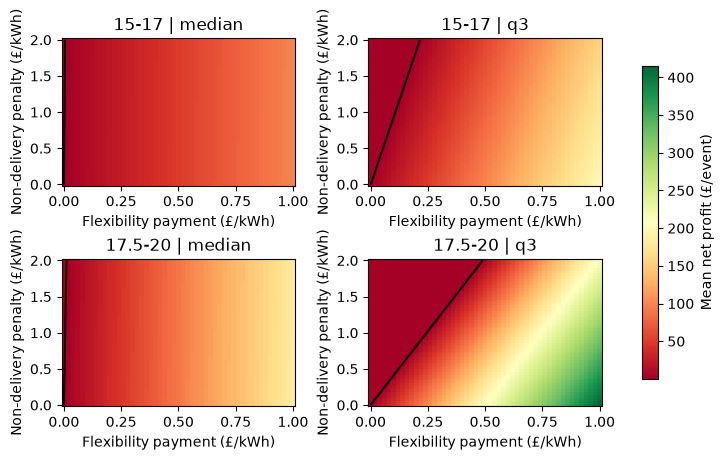

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#from matplotlib.colors import TwoSlopeNorm

df = pd.read_csv("flex_res_results/test_results.csv")

# Handle boolean values stored as strings
df["valid"] = (
    df["valid"].astype(str).str.lower() == "true"
)
df = df[df["valid"]].copy()

durations = {"15-17": 2.0, "17.5-20": 2.5}

payments = np.linspace(0, 1, 51)
penalties = np.linspace(0, 2, 51)
RHO, KAPPA = np.meshgrid(payments, penalties)

results = {}

for window in durations:
    for strategy in ["median", "q3"]:

        sub = df[
            (df["window"] == window) &
            (df["strategy"] == strategy)
        ]

        if sub.empty:
            continue

        H = durations[window]

        profit = (
            RHO * H * sub["bid_kw"].mean()
            - KAPPA * H * sub["shortfall_kw"].mean()
            - sub["extra_bill_gbp"].mean()
        )

        results[(window, strategy)] = profit

# Shared symmetric color scale
vmax = max(
    np.max(np.abs(z)) for z in results.values()
)
vmax = max(vmax, 1e-9)

vmin = min(
    np.min(np.abs(z)) for z in results.values()
)
#vmin = min(vmin, -1e-9)


fig, axes = plt.subplots(
    2, 2, figsize=set_size(516), constrained_layout=True
)

for ax, ((window, strategy), Z) in zip(
    axes.flat, results.items()
):

    im = ax.pcolormesh(
        RHO, KAPPA, Z,
        cmap="RdYlGn",
        vmin=vmin,
        vmax=vmax,
        shading="auto"
)
    """
    im = ax.pcolormesh(
        RHO, KAPPA, Z,
        cmap="RdYlGn",
        norm=TwoSlopeNorm(
            vmin=vmin, vcenter=0, vmax=vmax
        ),
        shading="auto"
    )
    """

    if Z.min() <= 0 <= Z.max():
        ax.contour(
            RHO, KAPPA, Z,
            levels=[0],
            colors="black",
            linewidths=1.5
        )

    ax.set_title(f"{window} | {strategy}")
    ax.set_xlabel("Flexibility payment (£/kWh)")
    ax.set_ylabel("Non-delivery penalty (£/kWh)")

fig.colorbar(
    im, ax=axes,
    label="Mean net profit (£/event)",
    shrink=0.85
)

#plt.savefig(
 #   "financial_sensitivity_per_event.png",
  #  dpi=300, bbox_inches="tight"
#)
plt.savefig(
    "financial_sensitivity_per_event.pdf",
    bbox_inches="tight"
)

plt.show()

## 3.2 Delivery rate

In [1]:
import numpy as np
import pandas as pd

df = pd.read_csv("flex_res_results/test_results.csv")

# Keep valid test cases
df = df[
    df["valid"].astype(str).str.lower() == "true"
].copy()

# Exclude zero bids (delivery ratio is undefined)
df = df[df["bid_kw"] > 0].copy()

# Recalculate ratio from delivered and contracted flexibility
df["ratio"] = df["delivered_kw"] / df["bid_kw"]

# Classify delivery
df["delivery_status"] = np.select(
    [
        df["ratio"] >= 0.90,
        df["ratio"] > 0.50
    ],
    [
        "Successful",
        "Partial",
    ],
    default="Failed"
)

# Compute percentages by window and strategy
summary = (
    pd.crosstab(
        [df["window"], df["strategy"]],
        df["delivery_status"],
        normalize="index"
    )
    .reindex(
        columns=["Successful", "Partial", "Failed"],
        fill_value=0
    )
    .mul(100)
    .round(2)
)

print(summary)

summary.to_csv("delivery_reliability_summary.csv")

delivery_status   Successful  Partial  Failed
window  strategy                             
15-17   median         99.35     0.33    0.33
        q3             61.11    37.91    0.98
17.5-20 median         99.02     0.65    0.33
        q3             29.41    62.75    7.84


# Prices and DoEs

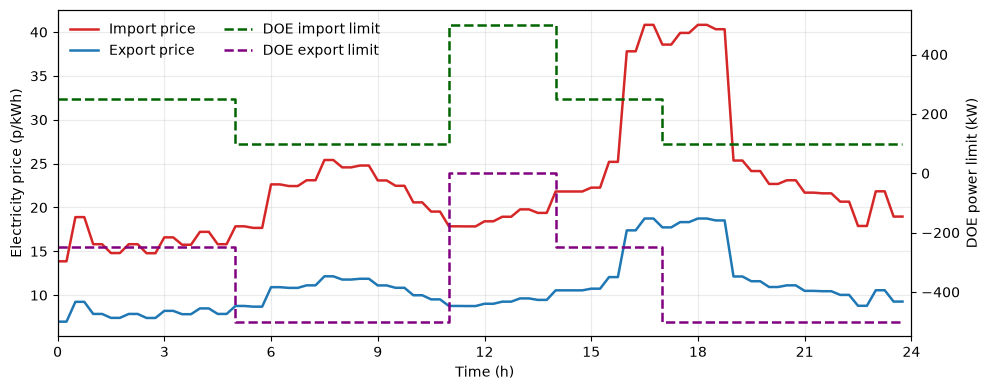

In [4]:
import matplotlib.pyplot as plt

time = np.arange(96) * 0.25  # Hours

fig, ax1 = plt.subplots(figsize=(10, 4))

# Left axis: Electricity prices (pence/kWh)
ax1.plot(time, price_imp, color="tab:red",
         label="Import price", linewidth=1.8)
ax1.plot(time, price_exp, color="tab:blue",
         label="Export price", linewidth=1.8)

ax1.set_xlabel("Time (h)")
ax1.set_ylabel("Electricity price (p/kWh)")
ax1.set_xlim(0, 24)
ax1.set_xticks(np.arange(0, 25, 3))
ax1.grid(alpha=0.25)

# Right axis: DOE limits (kW)
ax2 = ax1.twinx()

ax2.step(time, doe_import, where="post",
         color="darkgreen", linestyle="--",
         label="DOE import limit", linewidth=1.8)

ax2.step(time, doe_export, where="post",
         color="purple", linestyle="--",
         label="DOE export limit", linewidth=1.8)

ax2.set_ylabel("DOE power limit (kW)")

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(lines1 + lines2, labels1 + labels2,
           loc="upper left", ncol=2, frameon=False)

fig.tight_layout()
#fig.savefig(OUTPUT_DIR / "prices_and_doe.png",
 #           dpi=300, bbox_inches="tight")
fig.savefig("prices_and_doe.pdf",
            bbox_inches="tight")

plt.show()